# MIES–INFA: partición oficial de Kaggle

Partimos de las variables cargadas en la primera celda: `X_train`, `X_test`, `y_train` y, solo para el docente, `y_test`. **No volvemos a dividir el dataset completo ni sustituimos la partición oficial.** Las subdivisiones internas de `X_train` sirven únicamente para validación.

Compararemos kNN con 100 vecinos, kNN con 5 vecinos, kNN ajustado por F1 macro y MLP ajustado por accuracy y por F1 macro. Limpieza, selección de hiperparámetros y elección del umbral no utilizan `y_test`. La evaluación docente está al final.


In [1]:
# Load the database "alertas_ninos_menores_5" and the table "alertas_ninos_menores_2anos_sintetico" into a pandas DataFrame
import pandas as pd

X_train = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/X_train_Kaggle.csv")
X_test = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/X_test_Kaggle.csv")
y_train = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/y_train_Kaggle.csv")

# Los estudiantes pueden ejecutar el notebook sin el archivo privado.
try:
    y_test = pd.read_csv("/Users/eugenio/Documents/ArtificialIntelligence/datasets/alertaNinosMenores24meses(Kaggle)/solutionsIdClassUsage.csv").drop(columns=['ID','Usage'])
except FileNotFoundError:
    y_test = None


## 1. Preparación a partir de las variables cargadas

`y_train` y `y_test` pueden ser DataFrames de una columna; para entrenar se usa una Series de etiquetas. No se imputa, escala ni cambia ninguna etiqueta. La plantilla define los IDs y el orden de las predicciones. En estos archivos la columna es `ID`, en mayúsculas.


In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, TunedThresholdClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             average_precision_score, classification_report,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)

SEED = 42
TARGET = 'alerta_desnutricion'
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datasets').is_dir())
data_dir = root / 'datasets/alertaNinosMenores24meses(Kaggle)'
solution_file = data_dir / 'solutionsIdClassUsage.csv'
out_dir = root / 'resources/challenges/mies_infa_results/kaggle_official'
out_dir.mkdir(parents=True, exist_ok=True)
y_train_labels = y_train[TARGET].copy() if isinstance(y_train, pd.DataFrame) else y_train.copy()
submission_template = pd.read_csv(data_dir / 'sample_submission_malnutrition.csv')
assert len(X_train) == len(y_train_labels) and X_train.index.equals(y_train_labels.index)
assert X_train.columns.equals(X_test.columns)
assert len(X_test) == len(submission_template)
assert y_train_labels.notna().all() and set(y_train_labels.unique()) == {0, 1}
print(f'Train oficial: {len(X_train):,}; test oficial: {len(X_test):,}')
display(y_train_labels.value_counts().rename('Registros').to_frame())


Train oficial: 70,000; test oficial: 30,000


,Registros
alerta_desnutricion,
0,62991
1,7009


## 2. Qué significa cada columna y qué se limpia

| Columna | Significado | Tratamiento |
|---|---|---|
| `edad_meses` | Edad en meses | Negativos y valores >24 se marcan como faltantes. Admitimos 24 por la convención de esta base. Conservamos indicadores separados de edad negativa y fuera de rango. |
| `peso_kg` | Peso en kg | Valores ≤0 o ≥30 se marcan como faltantes. El bloque aislado 30–60 corresponde a la contaminación de este dataset sintético; no es un umbral clínico universal. |
| `talla_cm` | Talla en cm | Valores ≤0 serían inválidos. Conservamos las tallas positivas observadas, incluyendo las bajas. |
| `sexo` | Categoría M/F | Normalización de texto y one-hot. |
| `region` | Costa, Sierra, Amazonía, Insular | Normalización de texto y one-hot, sin imponer orden. |
| `nivel_educacion_madre` | Nivel educativo | Normalización de texto y one-hot. |
| `alerta_desnutricion` | Objetivo binario | Se conserva sin cambios; nunca entra al preprocesamiento de X. |

**No se borran filas, duplicados ni índices.** Un valor sospechoso se convierte en `NaN`; cada pipeline aprende cómo imputarlo usando solo su entrenamiento. No aplicamos una eliminación genérica por IQR: un peso o talla bajos pueden ser la señal que se quiere detectar. Tampoco normalizamos las categorías usando estadísticas del test.


Faltantes originales  Valores invalidados  Faltantes tras limpieza
Conjunto Columna                                                                                  
X_train  edad_meses                                0                 7084                     7084
         sexo                                      0                    0                        0
         region                                    0                    0                        0
         nivel_educacion_madre                     0                    0                        0
         peso_kg                                3469                  684                     4153
         talla_cm                               7049                    0                     7049
X_test   edad_meses                                0                 2998                     2998
         sexo                                      0                    0                        0
         region                                    0                    0                        0
         nivel_educacion_madre                     0                    0                        0
         peso_kg                                1483                  331                     1814
         talla_cm                               2951                    0                     2951

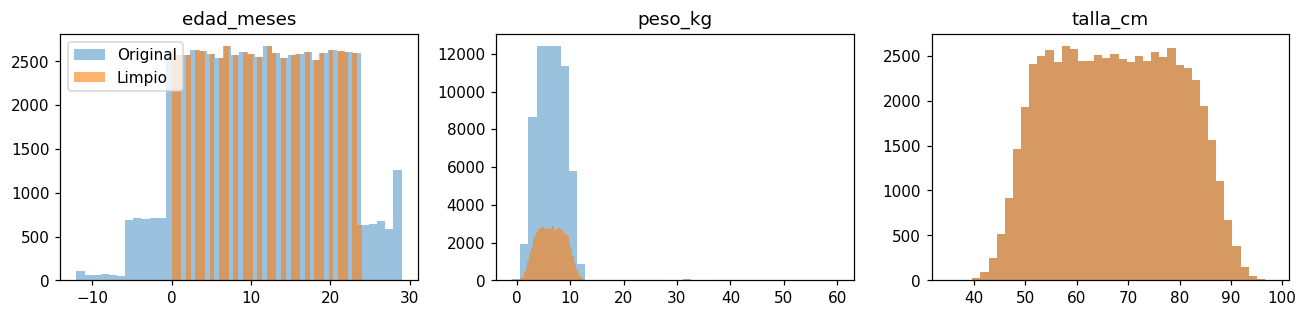

In [3]:
NUMERIC = ['edad_meses', 'peso_kg', 'talla_cm']
CATEGORIES = {
    'sexo': ['M', 'F'],
    'region': ['Costa', 'Sierra', 'Amazonía', 'Insular'],
    'nivel_educacion_madre': ['Sin escolaridad', 'Primaria', 'Secundaria', 'Superior']
}

def clean_data(data):
    z = data.copy()
    z[NUMERIC] = z[NUMERIC].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    z['edad_negativa'] = (z.edad_meses < 0).astype(int)
    z['edad_fuera_rango'] = ((z.edad_meses < 0) | (z.edad_meses > 24)).astype(int)
    z['peso_invalido'] = ((z.peso_kg <= 0) | (z.peso_kg >= 30)).astype(int)
    z.loc[z.edad_meses.lt(0) | z.edad_meses.gt(24), 'edad_meses'] = np.nan
    z.loc[z.peso_kg.le(0) | z.peso_kg.ge(30), 'peso_kg'] = np.nan
    z.loc[z.talla_cm.le(0), 'talla_cm'] = np.nan
    for column, allowed in CATEGORIES.items():
        text = z[column].astype('string').str.strip().str.casefold()
        z[column] = text.map({value.casefold(): value for value in allowed})
    assert len(z) == len(data) and z.index.equals(data.index)
    return z

def audit_features(data):
    cleaned = clean_data(data)
    return pd.DataFrame({
        'Faltantes originales': data.isna().sum(),
        'Valores invalidados': (data.notna() & cleaned[data.columns].isna()).sum(),
        'Faltantes tras limpieza': cleaned[data.columns].isna().sum()
    })

audit = pd.concat({'X_train': audit_features(X_train), 'X_test': audit_features(X_test)},
                  names=['Conjunto', 'Columna'])
display(audit)
audit.to_csv(out_dir / 'auditoria_train_test.csv')
# Inspección de las variables de entrenamiento; no usa el objetivo de test.
X_train_clean = clean_data(X_train)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, column in zip(axes, NUMERIC):
    ax.hist(X_train[column].dropna(), bins=40, alpha=0.45, label='Original')
    ax.hist(X_train_clean[column].dropna(), bins=40, alpha=0.6, label='Limpio')
    ax.set_title(column)
axes[0].legend()
plt.tight_layout()
plt.show()


### Qué reveló la revisión del generador y de los archivos guardados

En `dbToKaggle_inec.ipynb`, las etiquetas se generan primero; luego se añaden faltantes y anomalías a las variables, y **después** se realiza la partición 70/30. Por eso el test de variables también contiene anomalías. No hay una operación posterior que cambie o “limpie” `y_test`.

La comprobación de procedencia de los archivos disponibles encontró coincidencia exacta (valores y orden) con la partición `test_size=0.3, random_state=42` del CSV completo guardado. Esta comprobación fue una auditoría separada: ese CSV completo no se carga ni se usa para entrenar en este notebook.

Distinguir dos cosas: **anomalías de X** (faltantes, edades negativas, pesos de 30–60 kg) y **aleatoriedad en la creación de y** (un término normal dentro de la función que genera la etiqueta). Que `y_test` contenga únicamente 0 y 1 no demuestra que su regla de generación sea determinista. No modificamos ninguna respuesta oficial.


## 3. Validación solo dentro de X_train

Reservamos el 20% del entrenamiento público para elegir modelo y umbral. El 80% restante se usa para entrenar y buscar hiperparámetros mediante 3 particiones internas. **X_test sigue intacto y no se usa como validación.** Después de congelar las decisiones, reentrenamos con todo X_train.

Las reglas fijas de limpieza se aplican a cada conjunto; las medianas, escalas y categorías se aprenden únicamente con el entrenamiento correspondiente de cada pipeline.


In [4]:
X_fit, X_threshold, y_fit, y_threshold = train_test_split(
    X_train, y_train_labels, test_size=0.20, stratify=y_train_labels, random_state=SEED)
assert set(X_fit.index).isdisjoint(X_threshold.index)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

numeric_clean = NUMERIC + ['edad_negativa', 'edad_fuera_rango', 'peso_invalido']

def model_pipeline(model, clean=True):
    preprocessing = ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                  StandardScaler()), numeric_clean if clean else NUMERIC),
        ('categorical', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
         list(CATEGORIES))
    ])
    return Pipeline([
        ('clean', FunctionTransformer(clean_data) if clean else 'passthrough'),
        ('preprocess', preprocessing),
        ('model', model)
    ])

warning_log = []

def quiet_call(action, *args):
    # Capture repeated warnings once per call; retain a diagnostic summary.
    with warnings.catch_warnings(record=True) as captured, threadpool_limits(limits=1):
        warnings.simplefilter('always', ConvergenceWarning)
        warnings.simplefilter('once', RuntimeWarning)
        result = action(*args)
    for warning in captured:
        if issubclass(warning.category, (ConvergenceWarning, RuntimeWarning)):
            warning_log.append({'Tipo': warning.category.__name__, 'Mensaje': str(warning.message)})
        else:
            warnings.warn(warning.message, warning.category)
    return result

def fit_quiet(estimator, features, target):
    quiet_call(estimator.fit, features, target)
    if hasattr(estimator, 'cv_results_'):
        for key, values in estimator.cv_results_.items():
            if key.startswith('mean_test'):
                assert np.isfinite(values).all(), 'La búsqueda produjo métricas no finitas.'
    if isinstance(estimator, Pipeline) and isinstance(estimator['model'], MLPClassifier):
        assert all(np.isfinite(w).all() for w in estimator['model'].coefs_)
    return estimator

def positive_probability(model, features):
    probabilities = quiet_call(model.predict_proba, features)
    assert np.isfinite(probabilities).all(), 'Probabilidades no finitas: revisar avisos numéricos.'
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    return probabilities[:, 1]

print(f'Ajuste: {len(X_fit):,}; validación de umbral: {len(X_threshold):,}; test oficial: {len(X_test):,}')


Ajuste: 56,000; validación de umbral: 14,000; test oficial: 30,000


## 4. kNN con 100 y 5 vecinos

Ambos usan el mismo preprocesamiento. Un k grande puede favorecer la mayoría; uno pequeño puede producir positivos y también aprender ruido. Añadimos un kNN de 5 vecinos sin invalidar anomalías como control para medir si la limpieza aporta algo; aun ese control debe imputar y escalar para poder entrenar.


In [5]:
models = {}
for k in [100, 5]:
    models[f'kNN k={k}'] = fit_quiet(
        model_pipeline(KNeighborsClassifier(n_neighbors=k, n_jobs=1)), X_fit, y_fit)
raw_knn = fit_quiet(model_pipeline(KNeighborsClassifier(n_neighbors=5, n_jobs=1), clean=False),
                    X_fit, y_fit)
print('kNN de 100 y 5 vecinos entrenados.')


kNN de 100 y 5 vecinos entrenados.


## 5. kNN: búsqueda maximizando F1 macro

F1 macro promedia el F1 de las dos clases con el mismo peso. La búsqueda cambia el número de vecinos y cómo votan. No garantiza un F1 alto si falta señal predictiva.


In [6]:
knn_search = GridSearchCV(
    model_pipeline(KNeighborsClassifier(n_jobs=1)),
    {'model__n_neighbors': [5, 15, 35, 100], 'model__weights': ['uniform', 'distance']},
    scoring='f1_macro', cv=cv, n_jobs=1, verbose=0, error_score='raise')
fit_quiet(knn_search, X_fit, y_fit)
models['kNN búsqueda F1 macro'] = knn_search.best_estimator_
print('Mejores parámetros kNN:', knn_search.best_params_)
print(f'F1 macro CV: {knn_search.best_score_:.3f}')


Mejores parámetros kNN: {'model__n_neighbors': 5, 'model__weights': 'distance'}
F1 macro CV: 0.502


## 6. MLP: búsqueda por accuracy y por F1 macro

Una búsqueda calcula ambas métricas para los mismos candidatos y particiones; seleccionamos y reentrenamos por separado el ganador de **accuracy** y el de **F1 macro**. Esto equivale a dos búsquedas con idéntica rejilla sin duplicar todos los entrenamientos. Los ganadores pueden coincidir.

`scoring` selecciona hiperparámetros; no cambia la función de pérdida con la que aprende la red. Usamos `early_stopping=False`: la parada temprana incorporada al MLP controla accuracy, aunque GridSearchCV evalúe F1 macro. El entrenamiento se detiene por la pérdida o el límite de iteraciones. No se imprimen iteraciones; los avisos de convergencia se resumen una sola vez.


In [7]:
mlp = MLPClassifier(max_iter=250, batch_size=512, learning_rate_init=0.001,
                    early_stopping=False, n_iter_no_change=15, tol=1e-4,
                    random_state=SEED, verbose=False)
mlp_search = GridSearchCV(
    model_pipeline(mlp),
    {'model__hidden_layer_sizes': [(16,), (32, 16)], 'model__alpha': [0.001, 0.1]},
    scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro'},
    refit=False, cv=cv, n_jobs=1, verbose=0, error_score='raise')
fit_quiet(mlp_search, X_fit, y_fit)
mlp_cv = pd.DataFrame(mlp_search.cv_results_)
display(mlp_cv[['params', 'mean_test_accuracy', 'mean_test_f1_macro']].round(4))
for score, name in [('accuracy', 'MLP búsqueda accuracy'), ('f1_macro', 'MLP búsqueda F1 macro')]:
    best = mlp_cv.loc[mlp_cv[f'mean_test_{score}'].idxmax(), 'params']
    models[name] = fit_quiet(clone(mlp_search.estimator).set_params(**best), X_fit, y_fit)
    print(name, best)


MLP búsqueda accuracy {'model__alpha': 0.001, 'model__hidden_layer_sizes': (16,)}
MLP búsqueda F1 macro {'model__alpha': 0.001, 'model__hidden_layer_sizes': (16,)}


,params,mean_test_accuracy,mean_test_f1_macro
0,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (16,)}",0.8999,0.4736
1,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': (32, 16)}",0.8998,0.4736
2,"{'model__alpha': 0.1, 'model__hidden_layer_sizes': (16,)}",0.8999,0.4736
3,"{'model__alpha': 0.1, 'model__hidden_layer_sizes': (32, 16)}",0.8999,0.4736


## 7. Dejar de predecir todo como 0: elegir el umbral en validación

En estos clasificadores, la decisión habitual usa aproximadamente 0.5, pero puede que ninguna probabilidad alcance ese valor. Comparamos **los mismos modelos** en una rejilla de umbrales y elegimos el mayor F1 macro en el conjunto reservado para este paso. Nunca elegimos con las respuestas de Kaggle.

Bajar el umbral puede aumentar recall y falsas alarmas. Si las probabilidades no discriminan, el umbral no inventa información. Usar F1 macro tampoco obliga a obtener el mismo F1 para cada clase.


In [8]:
threshold_grid = np.linspace(0.02, 0.50, 97)
selection_rows = []
for name, model in models.items():
    probabilities = positive_probability(model, X_threshold)
    scores = [f1_score(y_threshold, probabilities >= t, average='macro', zero_division=0)
              for t in threshold_grid]
    best_index = int(np.argmax(scores))
    selection_rows.append({'Modelo': name, 'Umbral': threshold_grid[best_index],
                           'F1 macro validación': scores[best_index],
                           'F1 macro sin ajuste': f1_score(y_threshold, (probabilities > 0.5).astype(int),
                                                          average='macro', zero_division=0)})
selection = pd.DataFrame(selection_rows).sort_values('F1 macro validación', ascending=False)
display(selection.round(4))
selected_name = selection.iloc[0]['Modelo']
selected_threshold = float(selection.iloc[0]['Umbral'])
selected_model = models[selected_name]
print(f'Selección congelada: {selected_name}; umbral = {selected_threshold:.3f}')
selection.to_csv(out_dir / 'seleccion_validacion.csv', index=False)


Selección congelada: MLP búsqueda accuracy; umbral = 0.150


,Modelo,Umbral,F1 macro validación,F1 macro sin ajuste
3,MLP búsqueda accuracy,0.150,0.5316,0.4736
4,MLP búsqueda F1 macro,0.150,0.5316,0.4736
2,kNN búsqueda F1 macro,0.225,0.5228,0.5071
1,kNN k=5,0.205,0.5213,0.4899
0,kNN k=100,0.165,0.5184,0.4736


## 8. Reentrenar y predecir sin leer y_test

Los cinco modelos se reentrenan con **todo X_train y y_train** usando los hiperparámetros elegidos. El ganador seleccionado en validación también recalibra su umbral por CV dentro de X_train. Esto no utiliza las respuestas de Kaggle.

Se generan las predicciones para el mismo X_test oficial. El envío conserva exactamente los IDs y el orden de la plantilla. Las copias limpiadas conservan todas las filas y llevan NaN e indicadores; la imputación permanece dentro de los pipelines. Los archivos de entrada no se sobrescriben.


In [9]:
final_models = {
    name: fit_quiet(clone(model), X_train, y_train_labels)
    for name, model in models.items()
}
raw_knn_final = fit_quiet(clone(raw_knn), X_train, y_train_labels)
final_model = TunedThresholdClassifierCV(
    clone(selected_model), scoring='f1_macro', thresholds=threshold_grid,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)
fit_quiet(final_model, X_train, y_train_labels)

# Todas estas predicciones se calculan antes de evaluar con las respuestas oficiales.
test_predictions = {'Siempre 0': np.zeros(len(X_test), dtype=int)}
test_probabilities = {'Siempre 0': np.full(len(X_test), y_train_labels.mean())}
for name, model in {'kNN k=5 sin limpiar': raw_knn_final, **final_models}.items():
    test_probabilities[name] = positive_probability(model, X_test)
    test_predictions[name] = (test_probabilities[name] > 0.5).astype(int)
final_name = 'Seleccionado + umbral'
test_probabilities[final_name] = positive_probability(final_model, X_test)
test_predictions[final_name] = quiet_call(final_model.predict, X_test).astype(int)

submission = submission_template.copy()
submission[TARGET] = test_predictions[final_name]
assert len(submission) == len(X_test)
assert submission['ID'].equals(submission_template['ID']) and submission['ID'].is_unique
assert set(submission[TARGET].unique()) <= {0, 1}
submission.to_csv(out_dir / 'submission_mies_f1macro.csv', index=False)
pd.DataFrame(test_predictions).assign(ID=submission_template['ID'].to_numpy()).to_csv(
    out_dir / 'predicciones_modelos.csv', index=False)
clean_data(X_train).to_csv(out_dir / 'X_train_clean_flags.csv', index=False)
clean_data(X_test).to_csv(out_dir / 'X_test_clean_flags.csv', index=False)
y_train_labels.to_frame(TARGET).to_csv(out_dir / 'y_train_sin_cambios.csv', index=False)
print(f'Modelo seleccionado por validación: {selected_name}; umbral final CV: {final_model.best_threshold_:.3f}')
print(f'Envío: {len(submission):,} filas, {submission[TARGET].sum():,} predicciones de clase 1.')
print(out_dir / 'submission_mies_f1macro.csv')


Modelo seleccionado por validación: MLP búsqueda accuracy; umbral final CV: 0.150
Envío: 30,000 filas, 6,127 predicciones de clase 1.
/Users/eugenio/Documents/ArtificialIntelligence/resources/challenges/mies_infa_results/kaggle_official/submission_mies_f1macro.csv


## 9. Solo docente: evaluación final en el test oficial

Esta sección usa `y_test` exclusivamente para medir las predicciones ya generadas. Los estudiantes no la necesitan: si no tienen el archivo de soluciones, se omite. Las respuestas no se limpian ni se imputan. Comprobamos ausencia de faltantes, dominio binario y alineación de IDs.

La tabla evalúa las 30.000 filas de test completas; no pretende reproducir por separado el leaderboard público/privado. **No se elige otro modelo ni se modifica el umbral después de consultar estos resultados.** Las salidas de esta sección son del docente; no deben incluirse en el notebook distribuido a participantes.


y_test: 30,000 etiquetas válidas, sin imputación ni cambios de clase.
              precision    recall  f1-score   support

           0      0.909     0.804     0.853     27009
           1      0.135     0.277     0.182      2991

    accuracy                          0.751     30000
   macro avg      0.522     0.541     0.518     30000
weighted avg      0.832     0.751     0.786     30000



,Accuracy,F1 macro,F1 clase 0,F1 clase 1,Recall 1,Precision 1,AP,Predicciones 1
Modelo,,,,,,,,
Siempre 0,0.9003,0.4738,0.9475,0.0000,0.0000,0.0000,0.0997,0
kNN k=5 sin limpiar,0.8883,0.4904,0.9407,0.0401,0.0234,0.1400,0.1171,500
kNN k=100,0.9003,0.4738,0.9475,0.0000,0.0000,0.0000,0.1386,0
kNN k=5,0.8890,0.4926,0.9411,0.0442,0.0257,0.1562,0.1184,493
kNN búsqueda F1 macro,0.8748,0.5052,0.9328,0.0776,0.0528,0.1462,0.1200,1081
MLP búsqueda accuracy,0.9003,0.4738,0.9475,0.0000,0.0000,0.0000,0.1361,0
MLP búsqueda F1 macro,0.9003,0.4738,0.9475,0.0000,0.0000,0.0000,0.1361,0
Seleccionado + umbral,0.7514,0.5177,0.8534,0.1821,0.2775,0.1355,0.1361,6127


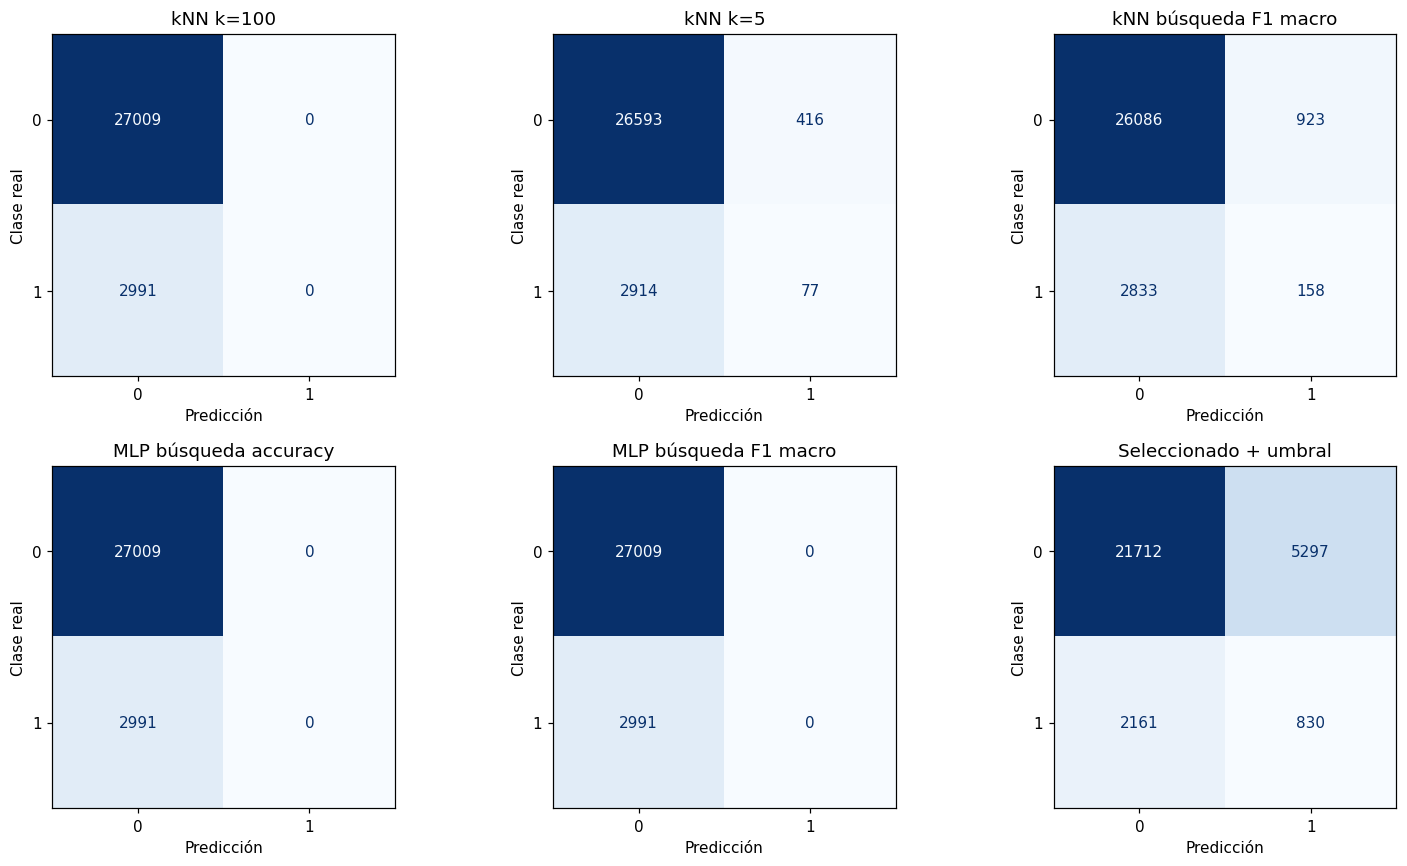

In [10]:
if y_test is None:
    print('Evaluación docente omitida: no se dispone de y_test. El envío ya está generado.')
else:
    # Mantener y_test original; solo seleccionar/alinear su columna objetivo.
    y_test_values = y_test[TARGET].copy() if isinstance(y_test, pd.DataFrame) else y_test.copy()
    assert len(y_test_values) == len(X_test) and y_test_values.notna().all()
    assert set(y_test_values.unique()) <= {0, 1}
    solution_metadata = pd.read_csv(solution_file, usecols=['ID', 'Usage'])
    assert len(solution_metadata) == len(y_test_values)
    assert solution_metadata['ID'].is_unique
    assert set(solution_metadata['ID']) == set(submission_template['ID'])
    y_test_by_id = pd.Series(y_test_values.to_numpy(), index=solution_metadata['ID'])
    y_test_docente = y_test_by_id.loc[submission_template['ID']].to_numpy()
    print(f'y_test: {len(y_test_docente):,} etiquetas válidas, sin imputación ni cambios de clase.')

    rows = []
    for name, pred in test_predictions.items():
        class_f1 = f1_score(y_test_docente, pred, labels=[0, 1], average=None, zero_division=0)
        rows.append({'Modelo': name, 'Accuracy': accuracy_score(y_test_docente, pred),
                     'F1 macro': class_f1.mean(), 'F1 clase 0': class_f1[0], 'F1 clase 1': class_f1[1],
                     'Recall 1': recall_score(y_test_docente, pred, zero_division=0),
                     'Precision 1': precision_score(y_test_docente, pred, zero_division=0),
                     'AP': average_precision_score(y_test_docente, test_probabilities[name]),
                     'Predicciones 1': int(pred.sum())})
    comparison = pd.DataFrame(rows).set_index('Modelo')
    display(comparison.round(4))
    comparison.to_csv(out_dir / 'comparacion_test_docente.csv')
    print(classification_report(y_test_docente, test_predictions[final_name], digits=3, zero_division=0))

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, name in zip(axes.flat, [*final_models, final_name]):
        ConfusionMatrixDisplay.from_predictions(y_test_docente, test_predictions[name], labels=[0, 1],
                                               ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(name)
        ax.set_xlabel('Predicción')
        ax.set_ylabel('Clase real')
    plt.tight_layout()
    plt.savefig(out_dir / 'matrices_test_docente.png', dpi=140)
    plt.show()


## 10. Interpretación y avisos resumidos

Compara los cinco experimentos antes de atribuir una mejora a la complejidad. F1 macro selecciona parámetros; no cambia la pérdida que optimiza el MLP. El umbral puede aumentar la detección y también las falsas alarmas. Revisa F1 por clase, recall, precisión y AP junto con accuracy.

El control kNN de 5 vecinos sin invalidar anomalías permite medir el efecto de la limpieza con el mismo entrenamiento. Limpiar variables no elimina el término aleatorio utilizado para generar las etiquetas.

Los avisos de convergencia o numéricos se resumen en vez de repetirse. Se comprueban métricas, pesos del MLP y probabilidades finitas; un fallo detiene la ejecución. Los avisos no se consideran resueltos por ocultar sus repeticiones.

Referencias: [pipelines y prevención de fuga](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [ajuste de umbral](https://scikit-learn.org/stable/modules/classification_threshold.html), [avisos de matmul en algunos Mac](https://github.com/numpy/numpy/issues/28687).


In [11]:
if warning_log:
    warning_summary = pd.DataFrame(warning_log).value_counts().rename('Veces registradas').reset_index()
    display(warning_summary)
    warning_summary.to_csv(out_dir / 'avisos_resumidos.csv', index=False)
else:
    print('Sin avisos de convergencia o numéricos.')


,Tipo,Mensaje,Veces registradas
0,RuntimeWarning,divide by zero encountered in matmul,41
1,RuntimeWarning,invalid value encountered in matmul,41
2,RuntimeWarning,overflow encountered in matmul,41
